# Previsão de Receita de Vendas — Comparação de Modelos

Análise para prever a receita gerada por vendedores a partir do tempo de experiência, número de vendas e fator sazonal. O objetivo é comparar modelos de regressão e identificar o mais eficiente.

## 1. Carregando e explorando os dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_csv("sales_data.csv")
df.head()

,tempo_de_experiencia,numero_de_vendas,fator_sazonal,receita_em_reais
0,36,21,5,2639.886941
1,74,44,10,4707.322227
2,38,44,4,5910.035131
3,52,62,6,6130.742546
4,97,56,2,7516.457681


In [3]:
print("Linhas e colunas:", df.shape)
df.info()

Linhas e colunas: (100, 4)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   tempo_de_experiencia  100 non-null    int64  
 1   numero_de_vendas      100 non-null    int64  
 2   fator_sazonal         100 non-null    int64  
 3   receita_em_reais      100 non-null    float64
dtypes: float64(1), int64(3)
memory usage: 3.3 KB


In [4]:
df.describe()

,tempo_de_experiencia,numero_de_vendas,fator_sazonal,receita_em_reais
count,100.000000,100.000000,100.000000,100.000000
mean,64.490000,54.490000,5.820000,5112.941924
std,32.397935,25.307201,2.836914,2544.731052
min,1.000000,10.000000,1.000000,1133.363948
25%,38.750000,37.500000,4.000000,2800.660516
50%,64.500000,52.500000,5.000000,4953.770034
75%,93.000000,70.500000,8.000000,7079.500163
max,119.000000,100.000000,10.000000,9941.016458


In [5]:
print("Valores nulos por coluna:")
df.isnull().sum()

Valores nulos por coluna:


tempo_de_experiencia    0
numero_de_vendas        0
fator_sazonal           0
receita_em_reais        0
dtype: int64

### Correlação entre as variáveis

In [6]:
df.corr().round(3)

,tempo_de_experiencia,numero_de_vendas,fator_sazonal,receita_em_reais
tempo_de_experiencia,1.000,0.043,-0.182,-0.043
numero_de_vendas,0.043,1.000,-0.093,0.077
fator_sazonal,-0.182,-0.093,1.000,0.032
receita_em_reais,-0.043,0.077,0.032,1.000


### Relação de cada variável com a receita

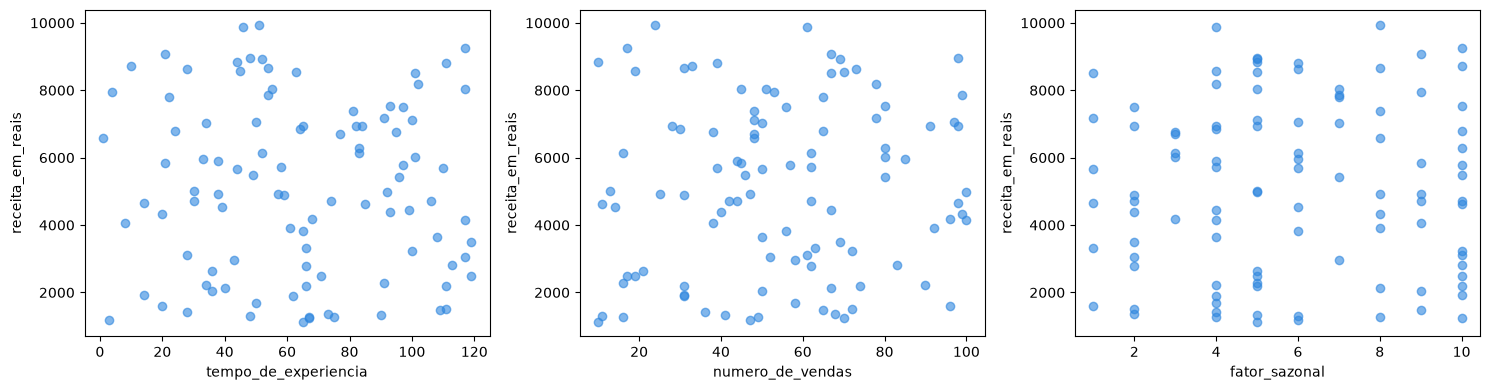

In [7]:
features = ["tempo_de_experiencia", "numero_de_vendas", "fator_sazonal"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
    ax.scatter(df[col], df["receita_em_reais"], color="#2E86DE", alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel("receita_em_reais")
plt.tight_layout()
plt.show()

## 2. Preparando os dados

In [8]:
X = df.drop(columns=["receita_em_reais"])
y = df["receita_em_reais"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Treino:", X_train.shape[0], "| Teste:", X_test.shape[0])

Treino: 80 | Teste: 20


## 3. Treinando e comparando modelos

In [9]:
modelos = {
    "Regressão Linear": LinearRegression(),
    "Regressão Polinomial": make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "Random Forest": RandomForestRegressor(random_state=42),
}

resultados = []
modelos_treinados = {}

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    resultados.append({
        "Modelo": nome,
        "R2": round(r2_score(y_test, pred), 4),
        "MAE": round(mean_absolute_error(y_test, pred), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_test, pred)), 2),
    })
    modelos_treinados[nome] = modelo

tabela = pd.DataFrame(resultados).sort_values("R2", ascending=False).reset_index(drop=True)
tabela

,Modelo,R2,MAE,RMSE
0,Regressão Polinomial,0.1225,1678.88,1995.86
1,Regressão Linear,-0.0660,1864.36,2199.78
2,Random Forest,-0.0709,1970.88,2204.89


## 4. Escolhendo e salvando o melhor modelo

In [10]:
melhor_nome = tabela.iloc[0]["Modelo"]
melhor_modelo = modelos_treinados[melhor_nome]

joblib.dump(melhor_modelo, "modelo_receita.pkl")
print("Melhor modelo:", melhor_nome)
print("Modelo salvo em modelo_receita.pkl")

Melhor modelo: Regressão Polinomial
Modelo salvo em modelo_receita.pkl


## Conclusões

- As três variáveis têm correlação muito baixa com a receita (todas perto de zero), então nenhum modelo consegue prever a receita com boa precisão.
- Entre os modelos testados, a Regressão Polinomial foi a menos ruim (maior R² e menor erro), sendo escolhida como a mais eficiente neste conjunto.
- A principal conclusão é que, com os dados disponíveis, tempo de experiência, número de vendas e fator sazonal não explicam bem a receita gerada. Para um modelo útil, seriam necessárias outras variáveis.
- O melhor modelo foi salvo em `modelo_receita.pkl` para ser usado no app de previsão (Gradio).